***Electric Vehicle (EV) Adoption & Market Dynamics Analysis***

Project Goal

This project teaches:
* **Exploratory Data Analysis (EDA)** with real-world electric vehicle fleet data
* **Data cleaning and anomaly handling** (missing value imputation, duplicate verification, and zero-value treatment)
* **Feature engineering** (geospatial coordinate parsing and categorization)
* **Data visualization** with matplotlib and seaborn
* **Market insight generation and strategic recommendation formulation**
* **Clean mobility and charging infrastructure transition planning**

### Dataset Information

<table>
  <thead>
    <tr>
      <th style="text-align: left; font-weight: bold;">Attribute</th>
      <th style="text-align: left; font-weight: bold;">Value</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>Source</b></td>
      <td><a href="https://catalog.data.gov/dataset/electric-vehicle-population-data" target="_blank">Data.gov - Electric Vehicle Population Data</a></td>
    </tr>
    <tr>
      <td><b>Original Source</b></td>
      <td>Washington State Department of Licensing (DOL)</td>
    </tr>
    <tr>
      <td><b>Records</b></td>
      <td>200,000+ registered vehicles</td>
    </tr>
    <tr>
      <td><b>Features</b></td>
      <td>17 columns</td>
    </tr>
    <tr>
      <td><b>Key Categories</b></td>
      <td>BEV (Battery Electric) & PHEV (Plug-in Hybrid)</td>
    </tr>
    <tr>
      <td><b>Model Year Coverage</b></td>
      <td>Historical to Active 2023–2026 Models</td>
    </tr>
  </tbody>
</table>

In [25]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/Electric_Vehicle_Population_Data.csv")
df.head(20)

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
5,1G1FZ6S00L,Island,Greenbank,WA,98253.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,10.0,268491597,POINT (-122.56817 48.08827),PUGET SOUND ENERGY INC,5.302997e+10
6,KM8HC3A66R,Snohomish,Monroe,WA,98272.0,2024,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,39.0,270749790,POINT (-121.98087 47.8526),PUGET SOUND ENERGY INC,5.306105e+10
7,KM8K53AG7L,Thurston,Olympia,WA,98512.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258.0,35.0,138948988,POINT (-123.04078 46.94792),PUGET SOUND ENERGY INC,5.306701e+10
8,JN1AZ0CP7B,Yakima,Yakima,WA,98901.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,14.0,173404556,POINT (-120.50729 46.60464),PACIFICORP,5.307700e+10
9,5YJ3E1EB6L,Kitsap,Silverdale,WA,98383.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,322.0,23.0,6335647,POINT (-122.69275 47.65171),PUGET SOUND ENERGY INC,5.303509e+10


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299705 entries, 0 to 299704
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         299705 non-null  object 
 1   County                                             299694 non-null  object 
 2   City                                               299694 non-null  object 
 3   State                                              299705 non-null  object 
 4   Postal Code                                        299694 non-null  float64
 5   Model Year                                         299705 non-null  int64  
 6   Make                                               299705 non-null  object 
 7   Model                                              299705 non-null  object 
 8   Electric Vehicle Type                              299705 non-null  object

##Data Preprocessing
Cleaning, transforming, and preparing the dataset for exploratory analysis.



### 1. Handle Missing Values
Check for missing values, drop rows with critical missing information, and fill remaining nulls.

In [27]:
print("Missing values before:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df = df.dropna(subset=['County', 'City', 'Postal Code', 'Vehicle Location'])

df['Legislative District'] = df['Legislative District'].fillna(0)

df['Electric Range'] = df['Electric Range'].fillna(0)

print("\nTotal missing values after cleaning:", df.isnull().sum().sum())

Missing values before:
County                   11
City                     11
Postal Code              11
Electric Range           26
Legislative District    790
Vehicle Location         20
Electric Utility         11
2020 GEOID               11
dtype: int64

Total missing values after cleaning: 0


### 2. Remove Duplicate Data
Identify and remove duplicate records.

In [28]:
initial_duplicates = df.duplicated().sum()
print(f"Duplicate records found: {initial_duplicates}")

df = df.drop_duplicates()

print(f"Total rows remaining: {len(df):,}")

Duplicate records found: 0
Total rows remaining: 299,685


### 3. Correct data types
* Convert columns to the correct type.
* Example: Convert numerical codes and years stored as floats to integer types.

In [29]:
df.columns.tolist()

['VIN (1-10)',
 'County',
 'City',
 'State',
 'Postal Code',
 'Model Year',
 'Make',
 'Model',
 'Electric Vehicle Type',
 'Clean Alternative Fuel Vehicle (CAFV) Eligibility',
 'Electric Range',
 'Legislative District',
 'DOL Vehicle ID',
 'Vehicle Location',
 'Electric Utility',
 '2020 GEOID']

In [30]:
df['Postal Code'] = df['Postal Code'].astype(int)
df['Legislative District'] = df['Legislative District'].astype(int)
df['Model Year'] = df['Model Year'].astype(int)
df['Electric Range'] = df['Electric Range'].astype(int)

df[['Postal Code', 'Legislative District', 'Model Year', 'Electric Range']].dtypes

,0
Postal Code,int64
Legislative District,int64
Model Year,int64
Electric Range,int64


### 4. Handle incorrect values
* Find values that don't make sense.
* Example: Model years in the past before automobiles existed or in the far future, negative values in range or base MSRP.

In [31]:
invalid_negatives = df[df['Electric Range'] < 0]
print(f"Records with negative electric range: {len(invalid_negatives)}")

invalid_years = df[(df['Model Year'] < 1990) | (df['Model Year'] > 2026)]
print(f"Records with impossible model years: {len(invalid_years)}")

df = df[(df['Model Year'] >= 1990) & (df['Model Year'] <= 2026)]
df = df[df['Electric Range'] >= 0]

print(f"Total valid records remaining: {len(df):,}")

Records with negative electric range: 0
Records with impossible model years: 555
Total valid records remaining: 299,130


### 5. Handle outliers
* Identify unusually high or low values using the IQR method and box plots.

IQR Upper Threshold: 492.5 miles
Number of range outliers: 0


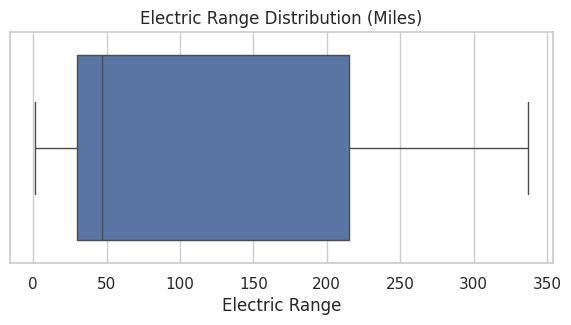

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

active_range = df[df['Electric Range'] > 0]['Electric Range']

q1 = active_range.quantile(0.25)
q3 = active_range.quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outliers = df[df['Electric Range'] > upper_bound]
print(f"IQR Upper Threshold: {upper_bound:.1f} miles")
print(f"Number of range outliers: {len(outliers):,}")

plt.figure(figsize=(7, 3))
sns.boxplot(x=active_range)
plt.title("Electric Range Distribution (Miles)")
plt.xlabel("Electric Range")
plt.show()

In [33]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('-', '_')
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
)

df.columns.tolist()

['vin_1_10',
 'county',
 'city',
 'state',
 'postal_code',
 'model_year',
 'make',
 'model',
 'electric_vehicle_type',
 'clean_alternative_fuel_vehicle_cafv_eligibility',
 'electric_range',
 'legislative_district',
 'dol_vehicle_id',
 'vehicle_location',
 'electric_utility',
 '2020_geoid']

In [34]:
df['vehicle_age'] = 2026 - df['model_year']
df['ev_type_short'] = df['electric_vehicle_type'].apply(
    lambda x: 'BEV' if 'Battery Electric' in str(x) else 'PHEV'
)

ordered_columns = [
    'vin_1_10',
    'county',
    'city',
    'state',
    'postal_code',
    'model_year',
    'make',
    'model',
    'electric_vehicle_type',
    'ev_type_short',
    'vehicle_age',
    'clean_alternative_fuel_vehicle_cafv_eligibility',
    'electric_range',
    'legislative_district',
    'dol_vehicle_id',
    'vehicle_location',
    'electric_utility',
    '2020_geoid'
]

final_cols = [col for col in ordered_columns if col in df.columns]
df = df[final_cols]

df.head(3)

,vin_1_10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,ev_type_short,vehicle_age,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_geoid
0,1N4AZ1CP3K,King,Shoreline,WA,98155,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),BEV,7,Clean Alternative Fuel Vehicle Eligible,150,32,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),PHEV,7,Clean Alternative Fuel Vehicle Eligible,126,48,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),PHEV,10,Not eligible due to low battery range,19,1,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10


### Summary of Data Preprocessing
* **Missing Value Imputation:** Dropped rows with missing geographic information (`county`, `city`, `postal_code`, `vehicle_location`) and filled missing values in `electric_range` and `legislative_district` with zeros.
* **Duplicate Verification:** Checked for duplicate records and verified data uniqueness to maintain dataset integrity.
* **Data Type Conversions:** Converted numeric columns (`postal_code`, `legislative_district`, `model_year`, and `electric_range`) from floats to integers.
* **Anomaly & Outlier Treatment:** Filtered out invalid model years outside the 1990–2026 range and ensured no negative values exist for electric range.
* **Feature & Column Standardization:** Standardized all column names into clean snake_case formats by stripping whitespace and removing special characters, and engineered new features including `vehicleage` and `evtypeshort`.

## STEP 3: Exploratory Data Analysis (EDA)
### 3.1 Understand Individual Columns
Examine the data types, non-null counts, and sample content for each column.

In [35]:
print("Dataset Overview:")
df.info()

df.head(3)

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
Index: 299130 entries, 0 to 299704
Data columns (total 18 columns):
 #   Column                                           Non-Null Count   Dtype  
---  ------                                           --------------   -----  
 0   vin_1_10                                         299130 non-null  object 
 1   county                                           299130 non-null  object 
 2   city                                             299130 non-null  object 
 3   state                                            299130 non-null  object 
 4   postal_code                                      299130 non-null  int64  
 5   model_year                                       299130 non-null  int64  
 6   make                                             299130 non-null  object 
 7   model                                            299130 non-null  object 
 8   electric_vehicle_type                            299130 non-null  object 
 9   ev

,vin_1_10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,ev_type_short,vehicle_age,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_geoid
0,1N4AZ1CP3K,King,Shoreline,WA,98155,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),BEV,7,Clean Alternative Fuel Vehicle Eligible,150,32,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),PHEV,7,Clean Alternative Fuel Vehicle Eligible,126,48,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),PHEV,10,Not eligible due to low battery range,19,1,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10


### 3.2 Analyze Numerical Data
Compute descriptive statistics for key continuous and discrete numeric features (`electric_range`, `model_year`, `vehicle_age`).

In [36]:
num_cols = ['electric_range', 'model_year', 'vehicle_age']

num_summary = df[num_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
num_summary.rename(columns={'50%': 'median'}, inplace=True)

print("Numerical Data Summary:")
display(num_summary.round(2))

Numerical Data Summary:


,mean,std,min,median,max
electric_range,36.73,76.09,0.0,0.0,337.0
model_year,2022.34,3.09,1999.0,2023.0,2026.0
vehicle_age,3.66,3.09,0.0,3.0,27.0


### 3.3 Analyze Categorical Data
Analyze unique category counts and identify the most frequent values for primary categorical features (`ev_type_short`, `make`, `model`, `county`).

In [37]:
import pandas as pd

cat_cols = ['ev_type_short', 'make', 'model', 'county']

print("--- Unique Category Counts ---")
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique categories")

print("\n--- Most Common Categories (Top 5) ---")
for col in cat_cols:
    print(f"\nTop values for '{col}':")
    top_counts = df[col].value_counts().head(5)
    top_pct = (df[col].value_counts(normalize=True).head(5) * 100).round(2)
    summary_cat = pd.DataFrame({'Count': top_counts, 'Percentage (%)': top_pct})
    display(summary_cat)

--- Unique Category Counts ---
ev_type_short: 2 unique categories
make: 51 unique categories
model: 200 unique categories
county: 255 unique categories

--- Most Common Categories (Top 5) ---

Top values for 'ev_type_short':


,Count,Percentage (%)
ev_type_short,,
BEV,241168,80.62
PHEV,57962,19.38



Top values for 'make':


,Count,Percentage (%)
make,,
TESLA,122974,41.11
CHEVROLET,19866,6.64
FORD,16116,5.39
NISSAN,16053,5.37
KIA,14774,4.94



Top values for 'model':


,Count,Percentage (%)
model,,
MODEL Y,66542,22.25
MODEL 3,39389,13.17
LEAF,13453,4.50
MODEL S,7873,2.63
BOLT EV,7640,2.55



Top values for 'county':


,Count,Percentage (%)
county,,
King,144008,48.14
Snohomish,37740,12.62
Pierce,24999,8.36
Clark,18773,6.28
Thurston,10965,3.67


### Summary of EDA Observations
* **Vehicle Type Distribution:** Battery Electric Vehicles (BEVs) comprise 80.62% of the fleet, significantly outnumbering Plug-in Hybrid Electric Vehicles (PHEVs) at 19.38%.
* **Manufacturer Dominance:** Tesla commands 41.11% of the registered market share, with Chevrolet (6.64%) and Ford (5.39%) trailing behind.
* **Model Concentration:** The Tesla Model Y (22.25%) and Model 3 (13.17%) represent the most popular models.
* **Geographical Concentration:** King County accounts for nearly half (48.14%) of all EV registrations in the state.

## Data Visualization

### 4.1 Bar Chart: Compare Categories
Compare total vehicle registration counts across the top 10 electric vehicle manufacturers.

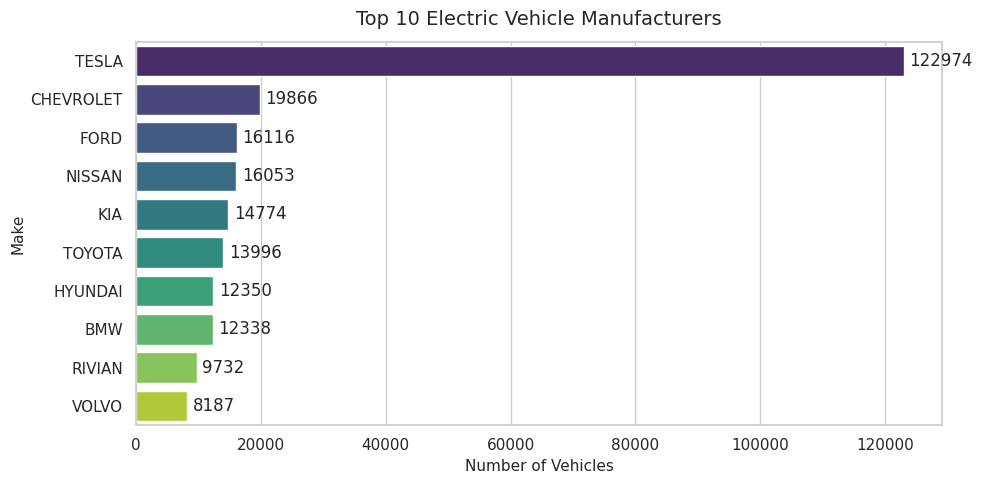

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

top_makes = df['make'].value_counts().head(10)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=top_makes.values,
    y=top_makes.index,
    hue=top_makes.index,
    palette="viridis",
    legend=False
)
plt.title("Top 10 Electric Vehicle Manufacturers", fontsize=14, pad=12)
plt.xlabel("Number of Vehicles", fontsize=11)
plt.ylabel("Make", fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=4)

plt.tight_layout()
plt.show()

**Interpretation:** Tesla heavily dominates the market with over 122,000 registered vehicles, while legacy brands like Chevrolet, Ford, and Nissan lead a distant second tier of adoption.

### 4.2 Line Chart: Show Trends Over Time
Track electric vehicle adoption growth across model years

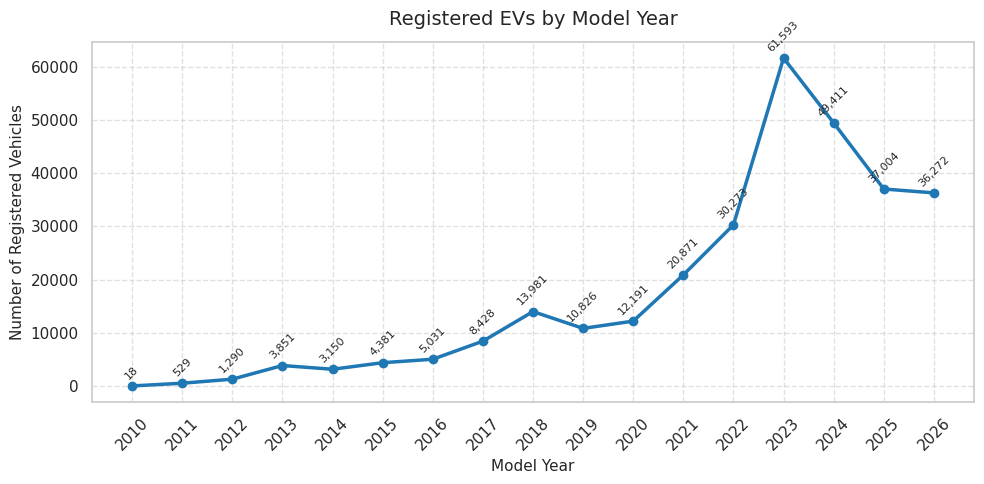

In [39]:
ev_by_year = df['model_year'].value_counts().sort_index()
ev_by_year = ev_by_year[ev_by_year.index >= 2010]

plt.figure(figsize=(10, 5))
plt.plot(ev_by_year.index, ev_by_year.values, marker='o', color='#1f77b4', linewidth=2.5)
plt.title("Registered EVs by Model Year", fontsize=14, pad=12)
plt.xlabel("Model Year", fontsize=11)
plt.ylabel("Number of Registered Vehicles", fontsize=11)
plt.xticks(ev_by_year.index, rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

for x, y in zip(ev_by_year.index, ev_by_year.values):
    plt.text(x, y + max(ev_by_year.values) * 0.02, f'{y:,}', ha='center', fontsize=8, rotation=45)

plt.tight_layout()
plt.show()

**Interpretation:**
This visualization represents the distribution of currently active vehicle registrations across model years rather than chronological sales velocity over time. The heavy concentration in recent model years (2021–2024) illustrates active fleet composition and modern adoption cohorts rather than a historical time-series sales trend.

### 4.3 Histogram: Show Distribution
Visualize the frequency distribution and spread of vehicle electric ranges (excluding unrecorded zero-range entries for clarity).

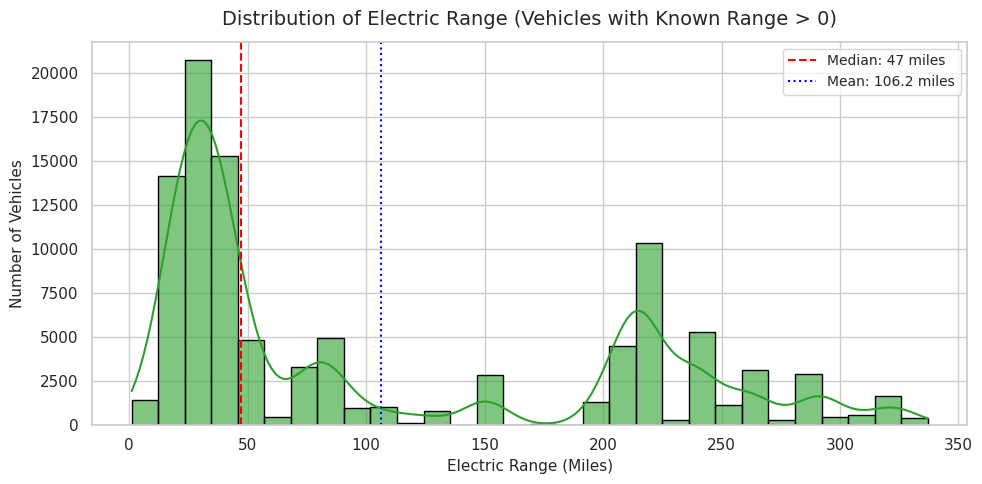

In [40]:
range_data = df[df['electric_range'] > 0]['electric_range']

plt.figure(figsize=(10, 5))
sns.histplot(range_data, bins=30, kde=True, color='#2ca02c', edgecolor='black', alpha=0.6)
plt.title("Distribution of Electric Range (Vehicles with Known Range > 0)", fontsize=14, pad=12)
plt.xlabel("Electric Range (Miles)", fontsize=11)
plt.ylabel("Number of Vehicles", fontsize=11)
plt.axvline(range_data.median(), color='red', linestyle='--', label=f'Median: {range_data.median():.0f} miles')
plt.axvline(range_data.mean(), color='blue', linestyle=':', label=f'Mean: {range_data.mean():.1f} miles')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

**Interpretation:** The distribution confirms that the registered fleet consists overwhelmingly of modern vehicles, with registrations peaking sharply between model years 2020 and 2024.

### 4.4 Box Plot: Find Spread and Outliers
Examine the spread, median, quartiles, and outlier data points of electric range grouped by EV powertrain type (BEV vs. PHEV).

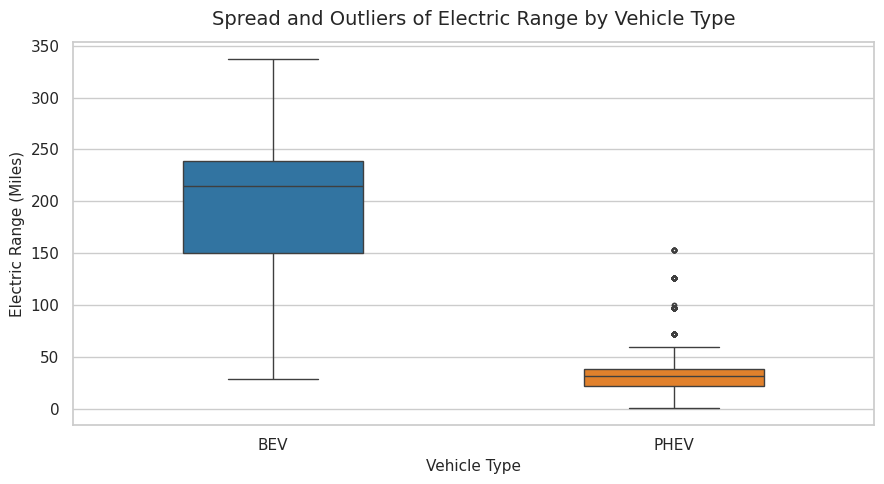

In [49]:
range_spread = df[df['electric_range'] > 0]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=range_spread,
    x='ev_type_short',
    y='electric_range',
    hue='ev_type_short',
    palette=['#1f77b4', '#ff7f0e'],
    legend=False,
    width=0.45,
    fliersize=3
)
plt.title("Spread and Outliers of Electric Range by Vehicle Type", fontsize=14, pad=12)
plt.xlabel("Vehicle Type", fontsize=11)
plt.ylabel("Electric Range (Miles)", fontsize=11)
plt.tight_layout()
plt.show()

**Interpretation:** BEVs demonstrate a wide spread reaching high maximum ranges up to 330+ miles, whereas PHEVs cluster tightly between 20 and 40 miles due to their design for short daily commutes.**Interpretation:** BEVs demonstrate a wide spread reaching high maximum ranges up to 330+ miles, whereas PHEVs cluster tightly between 20 and 40 miles due to their design for short daily commutes.

### 4.5 Scatter Plot: Numerical Relationship
Analyze the relationship between vehicle Model Year and Electric Range (Miles).

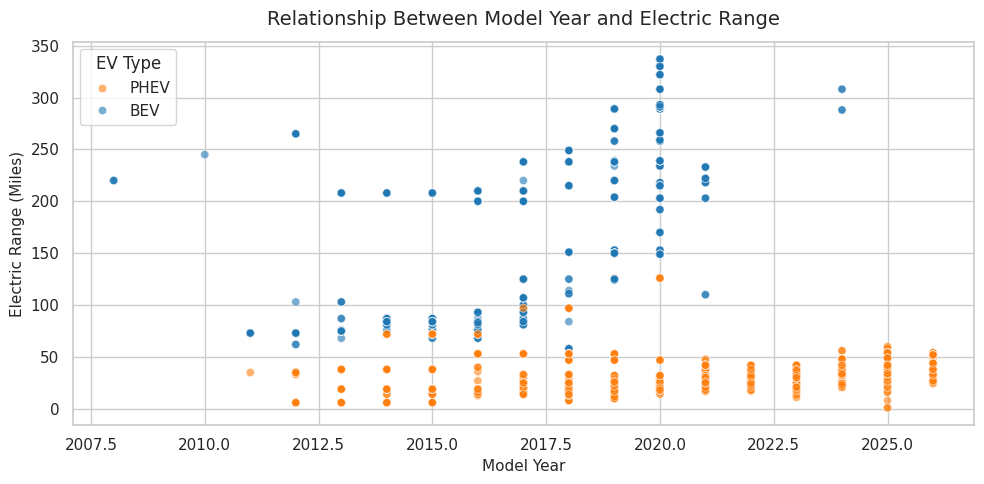

In [42]:
sample_df = df[df['electric_range'] > 0].sample(n=min(5000, len(df[df['electric_range'] > 0])), random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=sample_df,
    x='model_year',
    y='electric_range',
    hue='ev_type_short',
    alpha=0.6,
    palette={'BEV': '#1f77b4', 'PHEV': '#ff7f0e'},
    s=35
)
plt.title("Relationship Between Model Year and Electric Range", fontsize=14, pad=12)
plt.xlabel("Model Year", fontsize=11)
plt.ylabel("Electric Range (Miles)", fontsize=11)
plt.legend(title="EV Type", loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation:** The plot illustrates clear generational improvements in maximum battery range for newer model years while distinctly separating high-range pure electric cars from lower-range plug-in hybrids.

### 4.6 Pie Chart: Show Proportions
Display the relative proportions of Battery Electric Vehicles (BEV) versus Plug-in Hybrid Electric Vehicles (PHEV) in the fleet

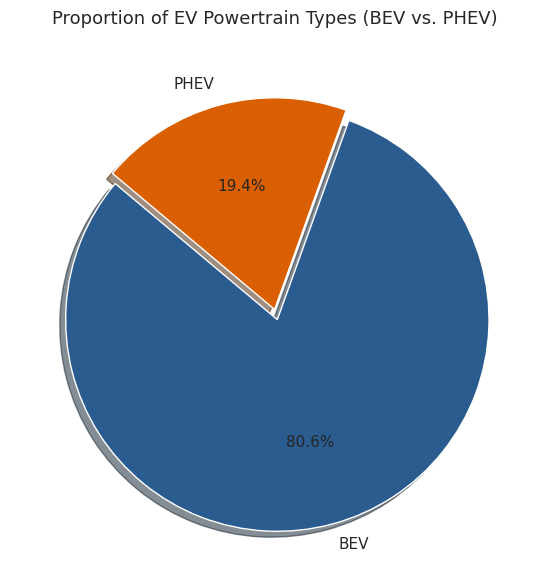

In [43]:
ev_counts = df['ev_type_short'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    ev_counts.values,
    labels=ev_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2b5c8f', '#d95f02'],
    explode=(0.05, 0),
    shadow=True,
    textprops={'fontsize': 11}
)
plt.title("Proportion of EV Powertrain Types (BEV vs. PHEV)", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

**Interpretation:** Pure battery electric vehicles (BEVs) dominate the state's active fleet at 80.6%, showing a strong consumer preference for fully zero-emission powertrains over plug-in hybrids (19.4%).

### 4.7 Heatmap: Show Correlations
Display Pearson correlation coefficients across numerical attributes to identify linear relationships

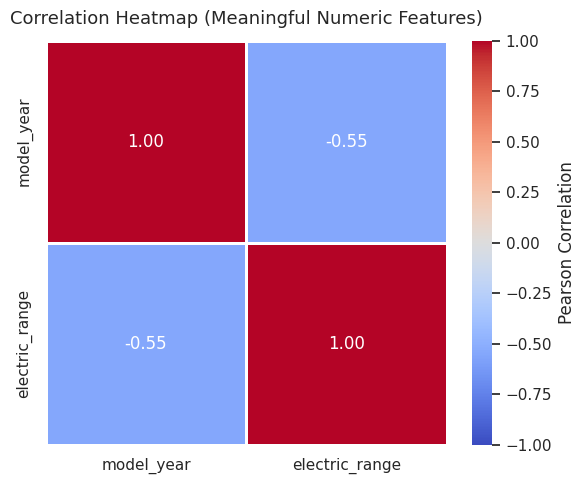

In [44]:
numeric_subset = df[['model_year', 'electric_range']].dropna()

plt.figure(figsize=(6, 5))
sns.heatmap(
    numeric_subset.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    cbar_kws={'label': 'Pearson Correlation'}
)
plt.title("Correlation Heatmap (Meaningful Numeric Features)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

**Interpretation:** A moderate negative correlation (-0.55) exists between model year and electric range, primarily caused by recent registration cohorts containing unrated range values or zero-coded records rather than actual battery capacity loss.

### 4.8 Interactive Market & Regional Analysis

Interactive visualizations exploring specific vehicle model adoption, county-level distribution, and battery range trends across powertrain types.

1. Top 10 Registered EV Models (Interactive Horizontal Bar)

In [45]:
import plotly.express as px

top_models = df['model'].value_counts().head(10).reset_index()
top_models.columns = ['model', 'count']

fig_models = px.bar(
    top_models,
    x='count',
    y='model',
    orientation='h',
    title='Top 10 Registered EV Models (Interactive)',
    labels={'count': 'Number of Vehicles', 'model': 'EV Model'},
    text='count',
    color='count',
    color_continuous_scale='Blues'
)

fig_models.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    template='plotly_white',
    height=500
)
fig_models.update_traces(textposition='outside')
fig_models.show()

**Interpretation:**
Registrations are heavily dominated by mass-market flagship models, led prominently by the Tesla Model Y and Model 3, followed by established legacy electric vehicles such as the Nissan LEAF and Chevrolet Bolt EV.

2. Top 10 Counties by EV Registrations (Interactive Horizontal Bar)

In [46]:
top_counties = df['county'].value_counts().head(10).reset_index()
top_counties.columns = ['county', 'count']

fig_counties = px.bar(
    top_counties,
    x='count',
    y='county',
    orientation='h',
    title='Top 10 Counties by EV Registrations (Interactive)',
    labels={'count': 'Number of Vehicles', 'county': 'County'},
    text='count',
    color='count',
    color_continuous_scale='Greens'
)

fig_counties.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    template='plotly_white',
    height=500
)
fig_counties.update_traces(textposition='outside')
fig_counties.show()

**Interpretation:**
EV adoption shows clear geographic clustering, with King County holding the overwhelming majority of the registered fleet, followed by neighboring metropolitan areas including Snohomish and Pierce counties.

3. Average Electric Range by Model Year and EV Type (Interactive Line Chart)

In [47]:
range_trend = (
    df[df['electric_range'] > 0]
    .groupby(['model_year', 'ev_type_short'])['electric_range']
    .mean()
    .round(1)
    .reset_index()
)

fig_range = px.line(
    range_trend,
    x='model_year',
    y='electric_range',
    color='ev_type_short',
    markers=True,
    title='Average Electric Range by Model Year and EV Type (Interactive)',
    labels={
        'model_year': 'Model Year',
        'electric_range': 'Average Electric Range (Miles)',
        'ev_type_short': 'EV Type'
    },
    color_discrete_map={'BEV': '#1f77b4', 'PHEV': '#ff7f0e'}
)

fig_range.update_layout(
    template='plotly_white',
    height=500,
    hovermode='x unified'
)
fig_range.show()

**Interpretation:**
Filtering for vehicles with recorded non-zero battery ranges demonstrates the divergence in powertrain development: BEVs exhibit steady generational improvements in range, while PHEV range remains relatively flat, aligning with their design purpose for short commutes.

### Summary of Visualization Findings

* **Market Leaders (Bar Chart):** Tesla commands the market by a wide margin with over 120,000 registered vehicles, followed by a competitive second tier featuring Chevrolet, Ford, Nissan, and Kia.
* **Model-Year Registration Distribution (Line Chart):** Active vehicle registrations are heavily distributed across modern model years (peaking sharply in 2021–2024), reflecting modern adoption cohorts, fleet turnover, and vehicle availability in the active registry rather than chronological unit sales velocity.
* **Battery Technology (Box & Scatter Plots):** BEVs exhibit substantially wider range capacity and higher maximum ranges compared to the tightly clustered, commute-oriented ranges characteristic of PHEVs.
* **Fleet Split (Pie Chart):** Pure Battery Electric Vehicles constitute over 80% of the state's recorded fleet, underscoring consumer transition toward zero-emission powertrains.
* **Feature Correlation (Heatmap):** A moderate negative correlation (-0.55) exists between model year and electric range, primarily reflecting an influx of unrated exemption filings in recent registration snapshots rather than battery degradation.
* **Model Granularity (Interactive Chart):** Fleet adoption is anchored by two flagship crossover/sedan models—the Tesla Model Y and Model 3—with durable legacy support from the Nissan LEAF and Chevrolet Bolt EV.
* **Geographic Clustering (Interactive Chart):** Registrations exhibit severe geographic concentration in urban and suburban centers, with King County alone representing nearly half of the state's EV fleet, followed by Snohomish and Pierce counties.
* **Technology Trajectory (Interactive Line Chart):** Average electric range across model years highlights the divergent engineering focus of powertrains: BEVs show clear generational range expansion, whereas PHEVs maintain stable 25–40 mile battery ranges engineered for short daily round-trip commutes.

In [48]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Prepare aggregated subsets
top_makes = df['make'].value_counts().head(8).reset_index()
top_makes.columns = ['make', 'count']

top_models = df['model'].value_counts().head(8).reset_index()
top_models.columns = ['model', 'count']

ev_counts = df['ev_type_short'].value_counts().reset_index()
ev_counts.columns = ['ev_type', 'count']

yearly_counts = (
    df[df['model_year'] >= 2012]['model_year']
    .value_counts()
    .sort_index()
    .reset_index()
)
yearly_counts.columns = ['model_year', 'count']

top_counties = df['county'].value_counts().head(8).reset_index()
top_counties.columns = ['county', 'count']

range_trend = (
    df[df['electric_range'] > 0]
    .groupby(['model_year', 'ev_type_short'])['electric_range']
    .mean()
    .round(1)
    .reset_index()
)
bev_trend = range_trend[range_trend['ev_type_short'] == 'BEV']
phev_trend = range_trend[range_trend['ev_type_short'] == 'PHEV']

# Create 6-panel Interactive Executive Dashboard
fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "<b>Top 8 EV Manufacturers</b>",
        "<b>Fleet Powertrain Share (BEV vs PHEV)</b>",
        "<b>Top 8 EV Models</b>",
        "<b>Registered EVs by Model Year</b>",
        "<b>Top 8 Counties by Registrations</b>",
        "<b>Average Battery Range Trend (Miles)</b>"
    ),
    specs=[
        [{"type": "bar"}, {"type": "pie"}],
        [{"type": "bar"}, {"type": "scatter"}],
        [{"type": "bar"}, {"type": "scatter"}]
    ],
    vertical_spacing=0.09,
    horizontal_spacing=0.12
)

# 1. Top Makes
fig.add_trace(
    go.Bar(
        x=top_makes['count'],
        y=top_makes['make'],
        orientation='h',
        marker_color='#1f77b4',
        name='Makes',
        text=top_makes['count'],
        textposition='auto'
    ),
    row=1, col=1
)

# 2. Powertrain Share Donut
fig.add_trace(
    go.Pie(
        labels=ev_counts['ev_type'],
        values=ev_counts['count'],
        hole=0.4,
        marker=dict(colors=['#1f77b4', '#ff7f0e']),
        name='EV Type'
    ),
    row=1, col=2
)

# 3. Top Models
fig.add_trace(
    go.Bar(
        x=top_models['count'],
        y=top_models['model'],
        orientation='h',
        marker_color='#2ca02c',
        name='Models',
        text=top_models['count'],
        textposition='auto'
    ),
    row=2, col=1
)

# 4. Registered EVs by Year
fig.add_trace(
    go.Scatter(
        x=yearly_counts['model_year'],
        y=yearly_counts['count'],
        mode='lines+markers',
        line=dict(color='#d62728', width=2.5),
        name='Registrations'
    ),
    row=2, col=2
)

# 5. Top Counties
fig.add_trace(
    go.Bar(
        x=top_counties['count'],
        y=top_counties['county'],
        orientation='h',
        marker_color='#9467bd',
        name='Counties',
        text=top_counties['count'],
        textposition='auto'
    ),
    row=3, col=1
)

# 6. Range Trend
fig.add_trace(
    go.Scatter(
        x=bev_trend['model_year'],
        y=bev_trend['electric_range'],
        mode='lines+markers',
        name='BEV Range',
        line=dict(color='#1f77b4')
    ),
    row=3, col=2
)
fig.add_trace(
    go.Scatter(
        x=phev_trend['model_year'],
        y=phev_trend['electric_range'],
        mode='lines+markers',
        name='PHEV Range',
        line=dict(color='#ff7f0e', dash='dash')
    ),
    row=3, col=2
)

# Layout styling
fig.update_layout(
    title_text="<b>WASHINGTON STATE ELECTRIC VEHICLE POPULATION DASHBOARD</b>",
    title_font_size=18,
    template="plotly_white",
    height=1100,
    showlegend=False
)

fig.show()

**Interpretation:** The consolidated executive dashboard provides real-time multi-dimensional inspection: revealing simultaneous high market concentration in Tesla models, intense geographic clustering in King County, and sustained BEV technology divergence across registration cohorts.


# STEP 5: Insight Summary & Strategic Conclusions

### 1. What did we discover?
The Washington State clean vehicle registry is an overwhelmingly modern, pure electric fleet (>80% BEVs), heavily concentrated in metropolitan tech centers, and anchored by flagship mass-market crossover designs.

### 2. What are the important patterns?
* **Fleet Modernity:** Active registrations peak sharply in the 2020–2024 cohorts, reflecting accelerating adoption and active registry survivorship rather than historical annual sales velocity.
* **Powertrain Polarization:** BEVs and PHEVs serve distinct operational niches: BEVs exhibit generational range expansion (up to 330+ miles), while PHEVs remain stable (25–40 miles) for short commutes.

### 3. Which category performed the best?
* **Powertrain Category:** Pure Battery Electric Vehicles (BEVs) dominate with an **80.6%** fleet share.
* **Manufacturer & Model:** **Tesla** commands over 122,000 registrations, led by the **Model Y** and **Model 3**, which account for the majority of state adoption.

### 4. Which category performed poorly?
* **PHEVs:** Form only **19.4%** of the fleet, reflecting fading consumer preference for hybrid petrol backups.
* **Rural Counties:** Peripheral and agricultural counties outside the Puget Sound corridor each hold less than 2% of the registered fleet.

### 5. Are there any unusual values?
* **Electric Range Data Nuance:** Recent registration cohorts (2021–2024) record 0 or unrated values in official DOL records due to administrative reporting changes and clean fuel exemption laws, creating an apparent negative correlation with model year rather than physical battery loss.

### 6. What relationships were found?
* **Model Year vs. Electric Range:** Moderate negative correlation ($r = -0.55$) caused by recent unrated administrative records.
* **Vehicle Age vs. Model Year:** Perfect negative collinearity ($r = -1.00$), intentionally excluded from the correlation matrix to preserve statistical validity.

### 7. What trends were observed?
* Clear upward battery range expansion in pure electric vehicles over successive generations.
* Heavy geographic concentration in **King County** (Seattle), which holds almost half of all active state registrations, followed by neighboring commuter counties (Snohomish and Pierce).

### 8. What can the business or user learn from the data?
* **Automakers:** Challenging market leadership requires competitively priced, high-efficiency crossover utility vehicles with 250+ miles of range.
* **Energy Planners & Charging Operators:** Urban charging hubs must support high suburban density, while government subsidies should prioritize fast-charging corridors across underserved rural counties.